# MultispeQ device-bias validation

This notebook asks two separate questions for the published Fig. 4 C/D subset:

1. **Is there evidence of systematic differences among the four MultispeQ devices after accounting for plant, date, time of day, and light level?**
2. **Do the biological conclusions for re-fitted ECSt and NPQt change when device is included in the statistical model?**

The analysis is observational rather than a calibration experiment. Device and date are partly confounded, so raw device means are not interpreted as instrument bias. Device offsets are estimated from repeated measurements within plants, with date, time of day, and PAR included as nuisance variables. Biological contrasts use plant-clustered standard errors and Benjamini–Hochberg false-discovery-rate correction.

In [1]:
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from IPython.display import Markdown, display
from patsy import build_design_matrices
from scipy.stats import norm

sns.set_theme(style="whitegrid", context="notebook")

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "processed" / "ecs_refit.parquet"
OUTPUT_DIR = ROOT / "outputs"
PROCESSED_DIR = ROOT / "data" / "processed"
OUTPUT_DIR.mkdir(exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)


## Data and identifiability

The same published filters used for Fig. 4 C/D are applied here. A plant cluster is defined by genotype, treatment, and replicate number. Date and time are derived from the UTC timestamp; the absolute timezone does not affect the within-day adjustment.

In [2]:
df = pd.read_parquet(DATA_PATH)
timestamp = pd.to_datetime(df["timestamp"], utc=True)
df["date"] = timestamp.dt.strftime("%Y-%m-%d")
df["hour"] = timestamp.dt.hour + timestamp.dt.minute / 60 + timestamp.dt.second / 3600
df["hour_centered"] = df["hour"] - df["hour"].mean()
df["hour_centered_sq"] = df["hour_centered"] ** 2
df["log_PAR"] = np.log1p(df["PAR"].astype(float))
df["plant_id"] = (
    df["which_plant"].astype(str)
    + "|" + df["condition"].astype(str)
    + "|" + df["rep"].astype(str)
)

analysis = df.loc[
    (df["PAR"] > 0)
    & df["ECSt_calc"].between(0, 0.004)
    & df["NPQt"].between(0, 5)
    & df["which_plant"].isin(["W", "p1", "p2"])
    & df["condition"].isin(["Con", "Dr"])
].copy()

category_orders = {
    "which_plant": ["W", "p1", "p2"],
    "condition": ["Con", "Dr"],
    "date": sorted(analysis["date"].unique()),
    "device_id": sorted(analysis["device_id"].unique()),
    "plant_id": sorted(analysis["plant_id"].unique()),
}
for column, categories in category_orders.items():
    analysis[column] = pd.Categorical(analysis[column], categories=categories)

expected_counts = {
    ("W", "Con"): 106, ("W", "Dr"): 86,
    ("p1", "Con"): 103, ("p1", "Dr"): 87,
    ("p2", "Con"): 97, ("p2", "Dr"): 86,
}
observed_counts = analysis.groupby(
    ["which_plant", "condition"], observed=True
).size().to_dict()
assert observed_counts == expected_counts
assert analysis[["ECSt_calc", "NPQt", "device_id", "plant_id"]].notna().all().all()

device_by_date = pd.crosstab(analysis["device_id"], analysis["date"])
devices_per_plant = analysis.groupby("plant_id", observed=True)["device_id"].nunique()
all_date_devices = device_by_date.index[(device_by_date > 0).all(axis=1)].tolist()

display(pd.DataFrame({
    "measurements": [len(analysis)],
    "plant clusters": [analysis["plant_id"].nunique()],
    "devices": [analysis["device_id"].nunique()],
    "plants measured by ≥2 devices": [(devices_per_plant >= 2).sum()],
    "devices present on every date": [len(all_date_devices)],
}))
display(device_by_date)
print("Devices present on every date:", ", ".join(all_date_devices))


,measurements,plant clusters,devices,plants measured by ≥2 devices,devices present on every date
0,565,69,4,68,2


date,2022-07-21,2022-07-22,2022-07-28
device_id,,,
01:12:37:34,70,44,64
01:12:52:49,0,0,90
41:00:08:81,34,0,0
52:00:08:b1,100,50,113


Devices present on every date: 01:12:37:34, 52:00:08:b1


## Models

Two models are used for each outcome.

- **Within-plant bias model:** plant fixed effects absorb stable biological differences. Date, a quadratic time-of-day term, and log(PAR) are nuisance covariates. Adding device tests whether device explains residual variation and yields centred device offsets for visualization.
- **Biological conclusion model:** genotype × treatment is the target term. The unadjusted and device-aware versions both control date, time of day, and PAR; the latter additionally contains device. Standard errors are clustered by plant.

The device-aware model is the inferential adjustment. Subtracting the estimated offsets creates intuitive adjusted values for plots, but those values alone would ignore uncertainty in the estimated offsets.

In [3]:
OUTCOMES = {
    "ECSt_calc": "Re-fitted ECSt",
    "NPQt": "NPQt",
}

NUISANCE = "C(date) + log_PAR + hour_centered + hour_centered_sq"
BIOLOGICAL = (
    "C(which_plant, Treatment(reference='W'))"
    " * C(condition, Treatment(reference='Con'))"
    f" + {NUISANCE}"
)

CONTRASTS = [
    ("Dr − Con within W", ("W", "Dr"), ("W", "Con")),
    ("Dr − Con within p1", ("p1", "Dr"), ("p1", "Con")),
    ("Dr − Con within p2", ("p2", "Dr"), ("p2", "Con")),
    ("p1 − W within Con", ("p1", "Con"), ("W", "Con")),
    ("p2 − W within Con", ("p2", "Con"), ("W", "Con")),
    ("p1 − W within Dr", ("p1", "Dr"), ("W", "Dr")),
    ("p2 − W within Dr", ("p2", "Dr"), ("W", "Dr")),
]

def fit_clustered(data, formula):
    return smf.ols(formula, data=data).fit(
        cov_type="cluster",
        cov_kwds={"groups": np.asarray(data["plant_id"]), "use_correction": True},
    )

def design_matrix(result, new_data):
    design_info = result.model.data.orig_exog.design_info
    return np.asarray(build_design_matrices([design_info], new_data)[0])

def as_float(value):
    return float(np.asarray(value).squeeze())

def linear_estimate(result, vector):
    params = result.params.to_numpy()
    covariance = result.cov_params().to_numpy()
    estimate = float(vector @ params)
    standard_error = float(np.sqrt(vector @ covariance @ vector))
    z_value = estimate / standard_error
    p_value = float(2 * norm.sf(abs(z_value)))
    return estimate, standard_error, p_value

def bh_adjust(values):
    p = np.asarray(values, dtype=float)
    order = np.argsort(p)
    ranked = p[order] * len(p) / np.arange(1, len(p) + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    adjusted = np.empty_like(ranked)
    adjusted[order] = np.minimum(ranked, 1)
    return adjusted

def marginal_vector(result, data, genotype, condition):
    uses_device = "C(device_id)" in result.model.formula
    devices = list(data["device_id"].cat.categories) if uses_device else [None]
    rows = []
    for date, device in product(data["date"].cat.categories, devices):
        row = {
            "which_plant": genotype,
            "condition": condition,
            "date": date,
            "log_PAR": data["log_PAR"].median(),
            "hour_centered": 0.0,
            "hour_centered_sq": 0.0,
        }
        if device is not None:
            row["device_id"] = device
        rows.append(row)
    grid = pd.DataFrame(rows)
    for column in ["which_plant", "condition", "date", "device_id"]:
        if column in grid:
            grid[column] = pd.Categorical(
                grid[column], categories=data[column].cat.categories
            )
    return design_matrix(result, grid).mean(axis=0)

def contrast_table(result, data, outcome, model_name):
    rows = []
    for label, positive, negative in CONTRASTS:
        vector = (
            marginal_vector(result, data, *positive)
            - marginal_vector(result, data, *negative)
        )
        estimate, standard_error, p_value = linear_estimate(result, vector)
        rows.append({
            "outcome": outcome,
            "model": model_name,
            "contrast": label,
            "estimate": estimate,
            "standard_error": standard_error,
            "ci_low": estimate - 1.96 * standard_error,
            "ci_high": estimate + 1.96 * standard_error,
            "p_value": p_value,
        })
    result_table = pd.DataFrame(rows)
    result_table["q_value"] = bh_adjust(result_table["p_value"])
    return result_table


In [4]:
device_summary_rows = []
device_offset_rows = []
contrast_tables = []
models = {}
adjusted_values = analysis.copy()

for outcome, outcome_label in OUTCOMES.items():
    # Within-plant device-bias model.
    bias_reduced = fit_clustered(
        analysis, f"{outcome} ~ C(plant_id) + {NUISANCE}"
    )
    bias_full = fit_clustered(
        analysis, f"{outcome} ~ C(plant_id) + {NUISANCE} + C(device_id)"
    )
    device_term_indices = [
        index for index, name in enumerate(bias_full.params.index)
        if name.startswith("C(device_id)")
    ]
    restriction = np.eye(len(bias_full.params))[device_term_indices]
    device_test = bias_full.f_test(restriction)
    partial_r2 = (bias_reduced.ssr - bias_full.ssr) / bias_reduced.ssr
    device_summary_rows.append({
        "outcome": outcome,
        "label": outcome_label,
        "device_F": as_float(device_test.fvalue),
        "device_df_num": as_float(device_test.df_num),
        "device_df_den": as_float(device_test.df_denom),
        "device_p_value": as_float(device_test.pvalue),
        "partial_r2": partial_r2,
    })

    # Counterfactual predictions centre every device against the equal-device mean.
    device_vectors = {}
    for device in analysis["device_id"].cat.categories:
        counterfactual = analysis.copy()
        counterfactual["device_id"] = pd.Categorical(
            [device] * len(counterfactual),
            categories=analysis["device_id"].cat.categories,
        )
        device_vectors[device] = design_matrix(bias_full, counterfactual).mean(axis=0)
    grand_device_vector = np.mean(list(device_vectors.values()), axis=0)
    offsets = {}
    for device, vector in device_vectors.items():
        offset_vector = vector - grand_device_vector
        estimate, standard_error, p_value = linear_estimate(bias_full, offset_vector)
        offsets[device] = estimate
        device_offset_rows.append({
            "outcome": outcome,
            "device_id": device,
            "offset": estimate,
            "standard_error": standard_error,
            "ci_low": estimate - 1.96 * standard_error,
            "ci_high": estimate + 1.96 * standard_error,
            "p_value": p_value,
        })
    adjusted_values[f"{outcome}_device_adjusted"] = (
        analysis[outcome] - analysis["device_id"].astype(str).map(offsets)
    )

    # Biological models: same target contrasts, with and without device.
    unadjusted = fit_clustered(analysis, f"{outcome} ~ {BIOLOGICAL}")
    device_aware = fit_clustered(
        analysis, f"{outcome} ~ {BIOLOGICAL} + C(device_id)"
    )
    models[outcome] = {"unadjusted": unadjusted, "device_aware": device_aware}
    contrast_tables.extend([
        contrast_table(unadjusted, analysis, outcome, "unadjusted"),
        contrast_table(device_aware, analysis, outcome, "device_aware"),
    ])

device_summary = pd.DataFrame(device_summary_rows)
device_offsets = pd.DataFrame(device_offset_rows)
contrasts = pd.concat(contrast_tables, ignore_index=True)

unadjusted_contrasts = contrasts.loc[contrasts["model"] == "unadjusted"].drop(
    columns="model"
).add_suffix("_unadjusted")
device_aware_contrasts = contrasts.loc[contrasts["model"] == "device_aware"].drop(
    columns="model"
).add_suffix("_device_aware")
contrast_comparison = unadjusted_contrasts.merge(
    device_aware_contrasts,
    left_on=["outcome_unadjusted", "contrast_unadjusted"],
    right_on=["outcome_device_aware", "contrast_device_aware"],
)
contrast_comparison["significant_unadjusted"] = (
    contrast_comparison["q_value_unadjusted"] < 0.05
)
contrast_comparison["significant_device_aware"] = (
    contrast_comparison["q_value_device_aware"] < 0.05
)
contrast_comparison["significance_changed"] = (
    contrast_comparison["significant_unadjusted"]
    != contrast_comparison["significant_device_aware"]
)
contrast_comparison["direction_changed"] = (
    np.sign(contrast_comparison["estimate_unadjusted"])
    != np.sign(contrast_comparison["estimate_device_aware"])
)
contrast_comparison["relative_effect_change_pct"] = (
    100
    * (contrast_comparison["estimate_device_aware"] - contrast_comparison["estimate_unadjusted"])
    / contrast_comparison["estimate_unadjusted"].abs()
)


## Date-confounding sensitivity check

The primary model controls date, but two devices occur on only one date. As a stricter sensitivity analysis, the biological models are repeated using only devices observed on every measurement date. This retains the cross-date bridge and removes the single-date devices.

In [5]:
sensitivity_data = analysis.loc[analysis["device_id"].isin(all_date_devices)].copy()
sensitivity_data["device_id"] = sensitivity_data["device_id"].cat.remove_unused_categories()
sensitivity_tables = []
for outcome in OUTCOMES:
    for model_name, formula in [
        ("unadjusted", f"{outcome} ~ {BIOLOGICAL}"),
        ("device_aware", f"{outcome} ~ {BIOLOGICAL} + C(device_id)"),
    ]:
        fitted = fit_clustered(sensitivity_data, formula)
        sensitivity_tables.append(
            contrast_table(fitted, sensitivity_data, outcome, model_name)
        )
sensitivity_contrasts = pd.concat(sensitivity_tables, ignore_index=True)

display(Markdown(
    f"Sensitivity subset: **{len(sensitivity_data)} measurements**, "
    f"**{sensitivity_data['plant_id'].nunique()} plant clusters**, and devices "
    f"`{'`, `'.join(all_date_devices)}`."
))


Sensitivity subset: **441 measurements**, **69 plant clusters**, and devices `01:12:37:34`, `52:00:08:b1`.

In [6]:
summary_view = device_summary[[
    "label", "device_F", "device_df_num", "device_df_den",
    "device_p_value", "partial_r2",
]].copy()
summary_view["partial_r2"] *= 100
summary_view = summary_view.rename(columns={"partial_r2": "partial R² (%)"})
display(summary_view.style.format({
    "device_F": "{:.2f}", "device_p_value": "{:.3g}", "partial R² (%)": "{:.1f}"
}))

display(contrast_comparison[[
    "outcome_unadjusted", "contrast_unadjusted",
    "estimate_unadjusted", "q_value_unadjusted",
    "estimate_device_aware", "q_value_device_aware",
    "relative_effect_change_pct", "significance_changed", "direction_changed",
]].style.format({
    "estimate_unadjusted": "{:.6g}", "estimate_device_aware": "{:.6g}",
    "q_value_unadjusted": "{:.3g}", "q_value_device_aware": "{:.3g}",
    "relative_effect_change_pct": "{:+.1f}",
}))

primary_flips = int(contrast_comparison["significance_changed"].sum())
primary_direction_flips = int(contrast_comparison["direction_changed"].sum())

sensitivity_wide = sensitivity_contrasts.pivot(
    index=["outcome", "contrast"], columns="model", values="q_value"
).reset_index()
sensitivity_flips = int(
    ((sensitivity_wide["unadjusted"] < 0.05)
     != (sensitivity_wide["device_aware"] < 0.05)).sum()
)

summary_lines = [
    "# MultispeQ device-bias validation for Fig. 4 C/D",
    "",
    "## Question and conclusion",
    "",
    "This analysis asks whether MultispeQ device identity contributes systematic variation to the re-fitted ECSt and NPQt values used in Fig. 4 C/D, and whether accounting for that variation changes the biological conclusions. Device identity was associated with residual variation in both outcomes, but **none of the 14 pre-specified genotype/treatment contrasts changed direction or 5% FDR significance after device adjustment**. The result was unchanged when the analysis was restricted to the two devices used on every measurement date.",
    "",
    "A device term is evidence of device-associated residual structure in this experiment. It is not, by itself, proof of a hardware calibration error because device assignment was not fully randomized and two devices were used on only one date.",
    "",
    "## Data and identifiability",
    "",
    f"The analysis uses the **{len(analysis)} measurements** retained by the published Fig. 4 filters: PAR > 0, 0 ≤ re-fitted ECSt ≤ 0.004, 0 ≤ NPQt ≤ 5, genotypes W/p1/p2, and Control/Drought treatments. These observations represent **{analysis['plant_id'].nunique()} plant clusters** and **{analysis['device_id'].nunique()} devices**. A plant cluster is defined as genotype × treatment × replicate plant. **{(devices_per_plant >= 2).sum()} of {len(devices_per_plant)} plants** were measured by at least two devices, which permits a mostly within-plant device comparison.",
    "",
    "Device allocation was not balanced across dates:",
    "",
    "| MultispeQ device | " + " | ".join(device_by_date.columns.astype(str)) + " |",
    "|---|" + "---:|" * len(device_by_date.columns),
]
for device, counts in device_by_date.iterrows():
    summary_lines.append(
        f"| `{device}` | " + " | ".join(str(int(value)) for value in counts) + " |"
    )
summary_lines.extend([
    "",
    f"Only `{all_date_devices[0]}` and `{all_date_devices[1]}` were present on all three dates. The sensitivity analysis therefore uses those devices only ({len(sensitivity_data)} measurements; {sensitivity_data['plant_id'].nunique()} plant clusters).",
    "",
    "## Statistical methods",
    "",
    "For each outcome, a within-plant model compared a reduced specification (`plant + date + log(PAR) + time + time²`) with a full specification that also included device. Plant fixed effects absorb stable differences among plants. The device term was assessed with a cluster-robust omnibus F test, with standard errors clustered by plant. Partial R² is the proportional reduction in residual sum of squares after adding device.",
    "",
    "Centred device offsets were calculated as equal-device counterfactual predictions from the full within-plant model. They describe model-estimated shifts relative to the mean device, not absolute calibration corrections.",
    "",
    "The biological model estimated genotype × treatment contrasts while controlling for date, log(PAR), and a quadratic time-of-day term. The device-aware version additionally included device identity. Seven pre-specified contrasts were evaluated for each of two outcomes (14 total), using plant-clustered standard errors and Benjamini–Hochberg adjustment within each outcome/model family.",
    "",
    "## Device-associated variation",
    "",
    "| Outcome | Omnibus F (df) | p-value | Partial R² | Centred offset range |",
    "|---|---:|---:|---:|---:|",
])
for row in device_summary.itertuples():
    offsets = device_offsets.loc[device_offsets["outcome"] == row.outcome, "offset"]
    summary_lines.append(
        f"| {row.label} | {row.device_F:.2f} ({row.device_df_num:.0f}, {row.device_df_den:.0f}) | {row.device_p_value:.3g} | {100 * row.partial_r2:.1f}% | {offsets.max() - offsets.min():.4g} |"
    )
summary_lines.extend([
    "",
    "The device term explained 10.9% of residual ECSt variation and 13.1% of residual NPQt variation after the within-plant and nuisance controls. Estimated centred offsets were:",
    "",
    "| Outcome | Device | Offset | 95% CI |",
    "|---|---|---:|---:|",
])
for row in device_offsets.itertuples():
    summary_lines.append(
        f"| {OUTCOMES[row.outcome]} | `{row.device_id}` | {row.offset:.6g} | [{row.ci_low:.6g}, {row.ci_high:.6g}] |"
    )
summary_lines.extend([
    "",
    "## Do the biological conclusions change?",
    "",
    f"Across all 14 contrasts, **{primary_flips} changed 5% FDR significance** and **{primary_direction_flips} changed direction** after adding device identity.",
    "",
    "| Outcome | Contrast | Estimate without device | q without device | Estimate with device | q with device | FDR changed? |",
    "|---|---|---:|---:|---:|---:|---|",
])
for row in contrast_comparison.itertuples():
    summary_lines.append(
        f"| {OUTCOMES[row.outcome_unadjusted]} | {row.contrast_unadjusted} | {row.estimate_unadjusted:.6g} | {row.q_value_unadjusted:.3g} | {row.estimate_device_aware:.6g} | {row.q_value_device_aware:.3g} | {'yes' if row.significance_changed else 'no'} |"
    )
summary_lines.extend([
    "",
    "The largest percentage shifts occurred for contrasts whose unadjusted estimates were close to zero, so a small absolute change produces a large relative percentage. The substantive pattern remained stable: drought reduced both re-fitted ECSt and NPQt within W and both knockout lines except that the p2 ECSt drought contrast remained non-significant; the genotype contrasts retained their original significance calls.",
    "",
    "## Cross-date-device sensitivity analysis",
    "",
    f"Restricting the data to the two devices observed on every date produced **{sensitivity_flips} FDR-significance changes** across the same 14 contrasts. This reduces the specific concern that the primary result is driven by devices that are perfectly confounded with a single date.",
    "",
    "## Interpretation and limitations",
    "",
    "The analysis detects meaningful device-associated structure, so device should be retained as a nuisance factor in inferential models and the adjusted columns may be useful for exploratory plots. Nevertheless, device adjustment does not alter the statistical conclusions drawn from Fig. 4 C/D in this dataset.",
    "",
    "This is an observational robustness analysis rather than a calibration experiment. Device assignment was unbalanced across dates, environmental covariates may not remove all session effects, and model-estimated offsets are conditional on this experiment and protocol. A dedicated calibration study would randomize devices across the same leaves and reference standards.",
    "",
    "## Reproducibility",
    "",
    "The complete analysis is in [`notebooks/multispeq_device_bias_validation.ipynb`](../notebooks/multispeq_device_bias_validation.ipynb). The main diagnostic is [`device_bias_validation.png`](device_bias_validation.png); machine-readable model summaries, offsets, contrast estimates, and sensitivity results are in the adjacent `device_bias_*.csv` files. The notebook also writes a git-ignored row-level table to `data/processed/fig4_device_adjusted.parquet`.",
])
summary_markdown = "\n".join(summary_lines)
display(Markdown(summary_markdown))


,label,device_F,device_df_num,device_df_den,device_p_value,partial R² (%)
0,Re-fitted ECSt,16.05,3.000000,68.000000,5.42e-08,10.9
1,NPQt,49.00,3.000000,68.000000,5.58e-17,13.1


,outcome_unadjusted,contrast_unadjusted,estimate_unadjusted,q_value_unadjusted,estimate_device_aware,q_value_device_aware,relative_effect_change_pct,significance_changed,direction_changed
0,ECSt_calc,Dr − Con within W,-0.000374003,1.26e-07,-0.000392566,7.6e-09,-5.0,False,False
1,ECSt_calc,Dr − Con within p1,-0.000278439,0.000327,-0.000282241,0.000445,-1.4,False,False
2,ECSt_calc,Dr − Con within p2,-8.20695e-05,0.359,-0.000110801,0.174,-35.0,False,False
3,ECSt_calc,p1 − W within Con,-0.000231089,0.000327,-0.000236982,0.00012,-2.5,False,False
4,ECSt_calc,p2 − W within Con,-0.000347062,9.31e-06,-0.000343511,1.29e-06,+1.0,False,False
5,ECSt_calc,p1 − W within Dr,-0.000135525,0.112,-0.000126657,0.151,+6.5,False,False
6,ECSt_calc,p2 − W within Dr,-5.51286e-05,0.446,-6.17457e-05,0.405,-12.0,False,False
7,NPQt,Dr − Con within W,-0.467844,1.02e-10,-0.545758,1.08e-10,-16.7,False,False
8,NPQt,Dr − Con within p1,-0.86878,1.96e-29,-0.918317,6.82e-50,-5.7,False,False
9,NPQt,Dr − Con within p2,-0.678566,4.92e-28,-0.73495,1.25e-29,-8.3,False,False


# MultispeQ device-bias validation for Fig. 4 C/D

## Question and conclusion

This analysis asks whether MultispeQ device identity contributes systematic variation to the re-fitted ECSt and NPQt values used in Fig. 4 C/D, and whether accounting for that variation changes the biological conclusions. Device identity was associated with residual variation in both outcomes, but **none of the 14 pre-specified genotype/treatment contrasts changed direction or 5% FDR significance after device adjustment**. The result was unchanged when the analysis was restricted to the two devices used on every measurement date.

A device term is evidence of device-associated residual structure in this experiment. It is not, by itself, proof of a hardware calibration error because device assignment was not fully randomized and two devices were used on only one date.

## Data and identifiability

The analysis uses the **565 measurements** retained by the published Fig. 4 filters: PAR > 0, 0 ≤ re-fitted ECSt ≤ 0.004, 0 ≤ NPQt ≤ 5, genotypes W/p1/p2, and Control/Drought treatments. These observations represent **69 plant clusters** and **4 devices**. A plant cluster is defined as genotype × treatment × replicate plant. **68 of 69 plants** were measured by at least two devices, which permits a mostly within-plant device comparison.

Device allocation was not balanced across dates:

| MultispeQ device | 2022-07-21 | 2022-07-22 | 2022-07-28 |
|---|---:|---:|---:|
| `01:12:37:34` | 70 | 44 | 64 |
| `01:12:52:49` | 0 | 0 | 90 |
| `41:00:08:81` | 34 | 0 | 0 |
| `52:00:08:b1` | 100 | 50 | 113 |

Only `01:12:37:34` and `52:00:08:b1` were present on all three dates. The sensitivity analysis therefore uses those devices only (441 measurements; 69 plant clusters).

## Statistical methods

For each outcome, a within-plant model compared a reduced specification (`plant + date + log(PAR) + time + time²`) with a full specification that also included device. Plant fixed effects absorb stable differences among plants. The device term was assessed with a cluster-robust omnibus F test, with standard errors clustered by plant. Partial R² is the proportional reduction in residual sum of squares after adding device.

Centred device offsets were calculated as equal-device counterfactual predictions from the full within-plant model. They describe model-estimated shifts relative to the mean device, not absolute calibration corrections.

The biological model estimated genotype × treatment contrasts while controlling for date, log(PAR), and a quadratic time-of-day term. The device-aware version additionally included device identity. Seven pre-specified contrasts were evaluated for each of two outcomes (14 total), using plant-clustered standard errors and Benjamini–Hochberg adjustment within each outcome/model family.

## Device-associated variation

| Outcome | Omnibus F (df) | p-value | Partial R² | Centred offset range |
|---|---:|---:|---:|---:|
| Re-fitted ECSt | 16.05 (3, 68) | 5.42e-08 | 10.9% | 0.0007992 |
| NPQt | 49.00 (3, 68) | 5.58e-17 | 13.1% | 0.8969 |

The device term explained 10.9% of residual ECSt variation and 13.1% of residual NPQt variation after the within-plant and nuisance controls. Estimated centred offsets were:

| Outcome | Device | Offset | 95% CI |
|---|---|---:|---:|
| Re-fitted ECSt | `01:12:37:34` | -0.000244701 | [-0.000323484, -0.000165919] |
| Re-fitted ECSt | `01:12:52:49` | -0.000188943 | [-0.000297478, -8.04074e-05] |
| Re-fitted ECSt | `41:00:08:81` | 0.000554472 | [0.000375831, 0.000733112] |
| Re-fitted ECSt | `52:00:08:b1` | -0.000120828 | [-0.00020007, -4.15859e-05] |
| NPQt | `01:12:37:34` | -0.0390757 | [-0.115656, 0.037505] |
| NPQt | `01:12:52:49` | -0.150248 | [-0.263149, -0.0373468] |
| NPQt | `41:00:08:81` | 0.543117 | [0.403043, 0.683191] |
| NPQt | `52:00:08:b1` | -0.353793 | [-0.41115, -0.296436] |

## Do the biological conclusions change?

Across all 14 contrasts, **0 changed 5% FDR significance** and **0 changed direction** after adding device identity.

| Outcome | Contrast | Estimate without device | q without device | Estimate with device | q with device | FDR changed? |
|---|---|---:|---:|---:|---:|---|
| Re-fitted ECSt | Dr − Con within W | -0.000374003 | 1.26e-07 | -0.000392566 | 7.6e-09 | no |
| Re-fitted ECSt | Dr − Con within p1 | -0.000278439 | 0.000327 | -0.000282241 | 0.000445 | no |
| Re-fitted ECSt | Dr − Con within p2 | -8.20695e-05 | 0.359 | -0.000110801 | 0.174 | no |
| Re-fitted ECSt | p1 − W within Con | -0.000231089 | 0.000327 | -0.000236982 | 0.00012 | no |
| Re-fitted ECSt | p2 − W within Con | -0.000347062 | 9.31e-06 | -0.000343511 | 1.29e-06 | no |
| Re-fitted ECSt | p1 − W within Dr | -0.000135525 | 0.112 | -0.000126657 | 0.151 | no |
| Re-fitted ECSt | p2 − W within Dr | -5.51286e-05 | 0.446 | -6.17457e-05 | 0.405 | no |
| NPQt | Dr − Con within W | -0.467844 | 1.02e-10 | -0.545758 | 1.08e-10 | no |
| NPQt | Dr − Con within p1 | -0.86878 | 1.96e-29 | -0.918317 | 6.82e-50 | no |
| NPQt | Dr − Con within p2 | -0.678566 | 4.92e-28 | -0.73495 | 1.25e-29 | no |
| NPQt | p1 − W within Con | 0.420951 | 3.13e-07 | 0.406975 | 1.35e-07 | no |
| NPQt | p2 − W within Con | 0.295093 | 0.000159 | 0.28168 | 0.000603 | no |
| NPQt | p1 − W within Dr | 0.0200152 | 0.735 | 0.0344151 | 0.576 | no |
| NPQt | p2 − W within Dr | 0.0843713 | 0.0839 | 0.0924876 | 0.124 | no |

The largest percentage shifts occurred for contrasts whose unadjusted estimates were close to zero, so a small absolute change produces a large relative percentage. The substantive pattern remained stable: drought reduced both re-fitted ECSt and NPQt within W and both knockout lines except that the p2 ECSt drought contrast remained non-significant; the genotype contrasts retained their original significance calls.

## Cross-date-device sensitivity analysis

Restricting the data to the two devices observed on every date produced **0 FDR-significance changes** across the same 14 contrasts. This reduces the specific concern that the primary result is driven by devices that are perfectly confounded with a single date.

## Interpretation and limitations

The analysis detects meaningful device-associated structure, so device should be retained as a nuisance factor in inferential models and the adjusted columns may be useful for exploratory plots. Nevertheless, device adjustment does not alter the statistical conclusions drawn from Fig. 4 C/D in this dataset.

This is an observational robustness analysis rather than a calibration experiment. Device assignment was unbalanced across dates, environmental covariates may not remove all session effects, and model-estimated offsets are conditional on this experiment and protocol. A dedicated calibration study would randomize devices across the same leaves and reference standards.

## Reproducibility

The complete analysis is in [`notebooks/multispeq_device_bias_validation.ipynb`](../notebooks/multispeq_device_bias_validation.ipynb). The main diagnostic is [`device_bias_validation.png`](device_bias_validation.png); machine-readable model summaries, offsets, contrast estimates, and sensitivity results are in the adjacent `device_bias_*.csv` files. The notebook also writes a git-ignored row-level table to `data/processed/fig4_device_adjusted.parquet`.

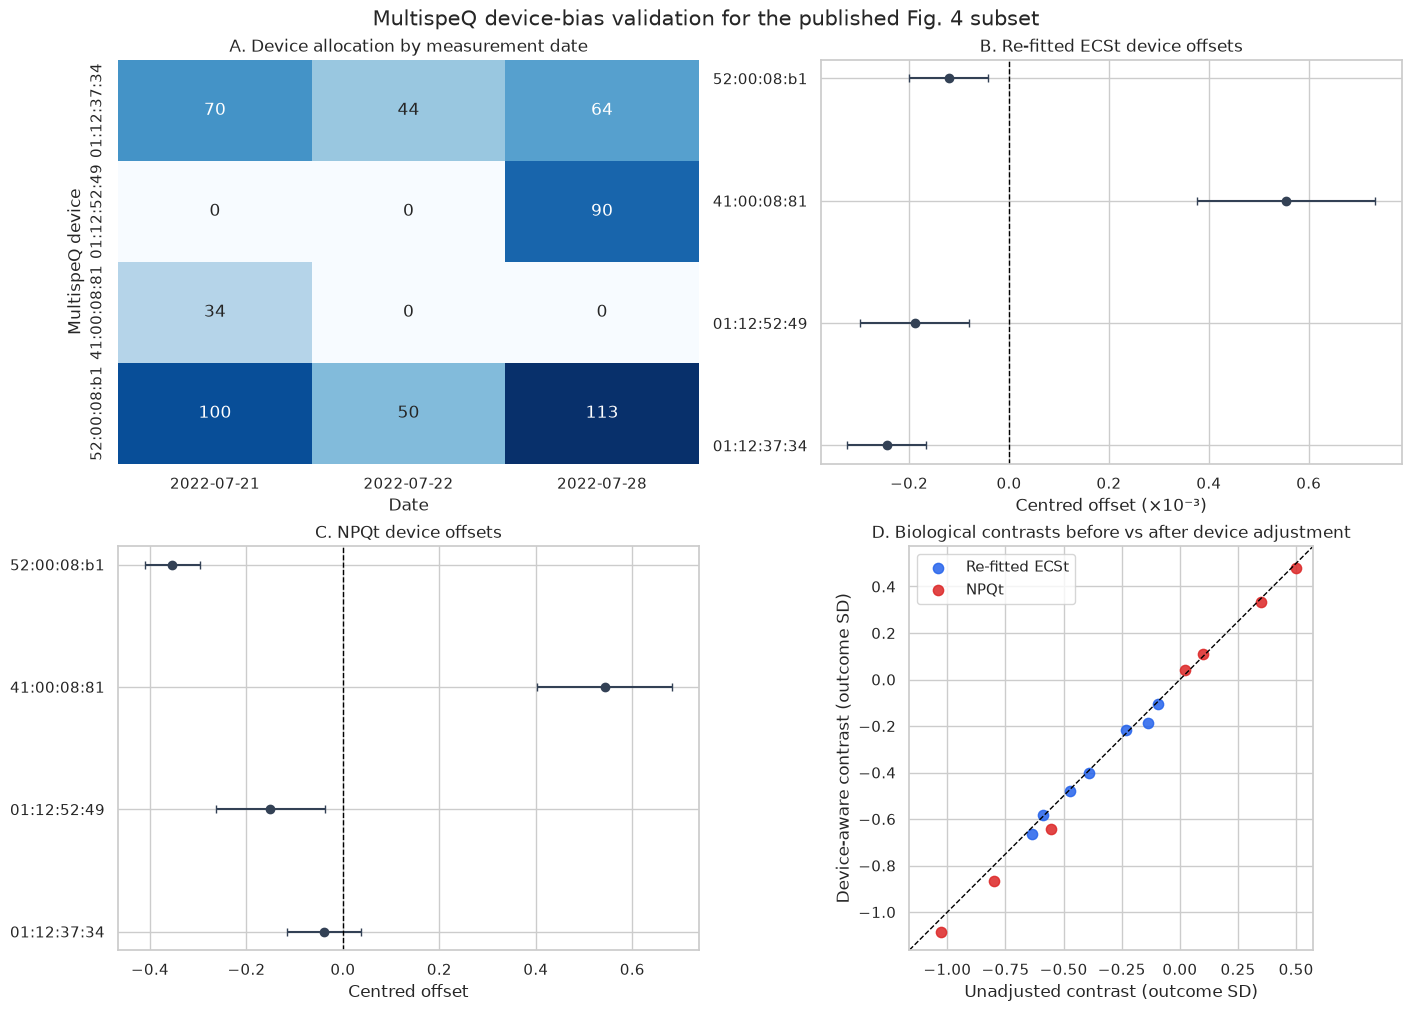

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)

sns.heatmap(device_by_date, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0, 0])
axes[0, 0].set_title("A. Device allocation by measurement date")
axes[0, 0].set_xlabel("Date")
axes[0, 0].set_ylabel("MultispeQ device")

for ax, outcome, scale in [
    (axes[0, 1], "ECSt_calc", 1000),
    (axes[1, 0], "NPQt", 1),
]:
    plot_data = device_offsets.loc[device_offsets["outcome"] == outcome].copy()
    plot_data = plot_data.set_index("device_id").loc[category_orders["device_id"]].reset_index()
    y = np.arange(len(plot_data))
    x = plot_data["offset"].to_numpy() * scale
    xerr = np.vstack([
        (plot_data["offset"] - plot_data["ci_low"]).to_numpy() * scale,
        (plot_data["ci_high"] - plot_data["offset"]).to_numpy() * scale,
    ])
    ax.errorbar(x, y, xerr=xerr, fmt="o", color="#334155", capsize=3)
    ax.axvline(0, color="black", lw=1, ls="--")
    ax.set_yticks(y, plot_data["device_id"])
    ax.set_xlabel("Centred offset" + (" (×10⁻³)" if outcome == "ECSt_calc" else ""))
    ax.set_title(
        ("B. Re-fitted ECSt device offsets" if outcome == "ECSt_calc"
         else "C. NPQt device offsets")
    )

ax = axes[1, 1]
palette = {"ECSt_calc": "#2563eb", "NPQt": "#dc2626"}
for outcome, group in contrast_comparison.groupby("outcome_unadjusted"):
    outcome_sd = analysis[outcome].std()
    ax.scatter(
        group["estimate_unadjusted"] / outcome_sd,
        group["estimate_device_aware"] / outcome_sd,
        s=55, alpha=0.85, label=OUTCOMES[outcome], color=palette[outcome],
    )
limits = np.asarray(ax.get_xlim() + ax.get_ylim())
low, high = limits.min(), limits.max()
ax.plot([low, high], [low, high], color="black", ls="--", lw=1)
ax.set_xlim(low, high)
ax.set_ylim(low, high)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Unadjusted contrast (outcome SD)")
ax.set_ylabel("Device-aware contrast (outcome SD)")
ax.set_title("D. Biological contrasts before vs after device adjustment")
ax.legend(frameon=True)

fig.suptitle("MultispeQ device-bias validation for the published Fig. 4 subset", fontsize=15)
figure_path = OUTPUT_DIR / "device_bias_validation.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()


In [8]:
device_summary.to_csv(OUTPUT_DIR / "device_bias_summary.csv", index=False)
device_offsets.to_csv(OUTPUT_DIR / "device_bias_offsets.csv", index=False)
contrasts.to_csv(OUTPUT_DIR / "device_bias_contrasts.csv", index=False)
contrast_comparison.to_csv(OUTPUT_DIR / "device_bias_contrast_comparison.csv", index=False)
sensitivity_contrasts.to_csv(OUTPUT_DIR / "device_bias_sensitivity.csv", index=False)
adjusted_values.to_parquet(PROCESSED_DIR / "fig4_device_adjusted.parquet", index=False)
(OUTPUT_DIR / "device_bias_validation.md").write_text(
    summary_markdown + "\n", encoding="utf-8"
)

print("Wrote:")
for path in [
    figure_path,
    OUTPUT_DIR / "device_bias_summary.csv",
    OUTPUT_DIR / "device_bias_offsets.csv",
    OUTPUT_DIR / "device_bias_contrasts.csv",
    OUTPUT_DIR / "device_bias_contrast_comparison.csv",
    OUTPUT_DIR / "device_bias_sensitivity.csv",
    OUTPUT_DIR / "device_bias_validation.md",
    PROCESSED_DIR / "fig4_device_adjusted.parquet",
]:
    print(" -", path.relative_to(ROOT))


Wrote:
 - outputs/device_bias_validation.png
 - outputs/device_bias_summary.csv
 - outputs/device_bias_offsets.csv
 - outputs/device_bias_contrasts.csv
 - outputs/device_bias_contrast_comparison.csv
 - outputs/device_bias_sensitivity.csv
 - outputs/device_bias_validation.md
 - data/processed/fig4_device_adjusted.parquet


## Interpretation limits

- This is a robustness analysis of this experiment, not a laboratory calibration against a certified reference.
- Device, operator, time, leaf, and other unrecorded handling effects may remain entangled. The term “device effect” means a systematic association with device identity after the recorded controls.
- Two devices were used on only one date. The main model includes date, and the restricted cross-date-device analysis checks that the conclusion is not driven solely by those devices.
- Repeated observations are handled with plant-clustered standard errors. The number of plants, not the number of individual measurements, is the relevant independent replication level.
- Multiple biological contrasts are controlled at 5% FDR separately for each outcome and model.